In [117]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Lasso, Ridge

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.model_selection import GridSearchCV

### Explore the Data

In [2]:
# Load the data
insurance_data = pd.read_csv("../dataset/insurance.csv")
df = insurance_data.copy()

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.tail(2)

,age,sex,bmi,children,smoker,region,charges
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [5]:
df.shape

(1338, 7)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.describe(include = "object")

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [14]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(1)

In [16]:
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [22]:
# Drop duplicate rows
df.drop_duplicates().reset_index(drop = True, inplace = True)

### Distribution of Target variables

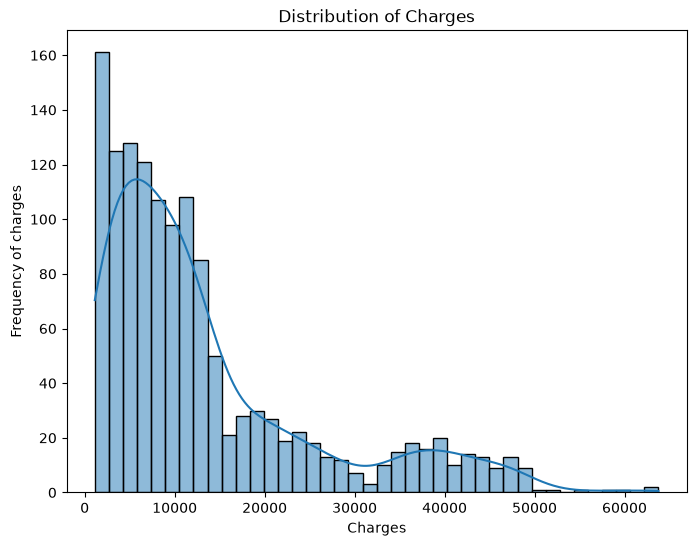

In [23]:
fig, ax = plt.subplots(figsize = (8,6))

sns.histplot(data = df, x = "charges", bins = 40, kde = True, ax = ax)

ax.set_title("Distribution of Charges")
ax.set_xlabel("Charges")
ax.set_ylabel("Frequency of charges")

plt.show()

## Exploratory Data Analysis

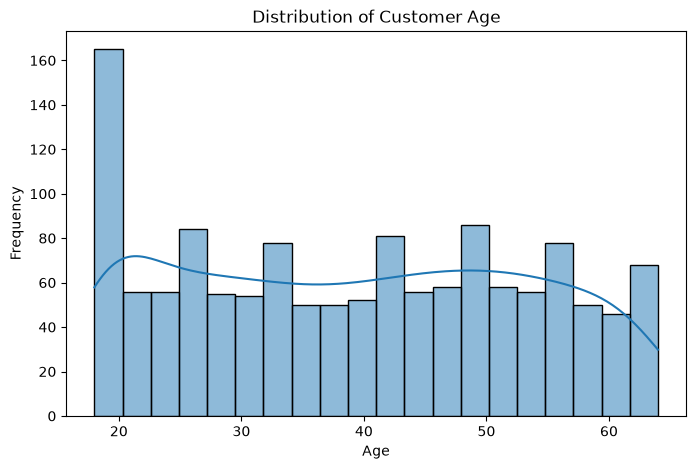

In [26]:
# Distribution of Age
plt.figure(figsize=(8, 5))

sns.histplot(df['age'], bins=20, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

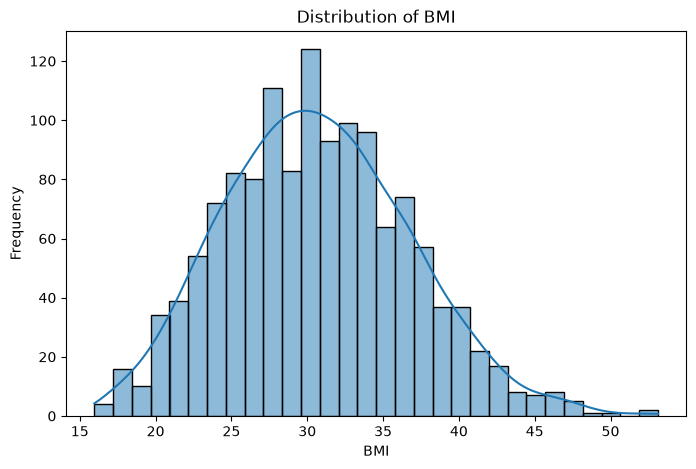

In [27]:
# Distribution of BMI
plt.figure(figsize=(8, 5))

sns.histplot(df['bmi'], bins=30, kde=True)

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.show()

In [29]:
# Distribution of Gender
df.groupby("sex")["charges"].agg(["count", "mean", "median"])

,count,mean,median
sex,,,
female,662,12569.578844,9412.9625
male,675,13974.998864,9377.9047


In [30]:
# Distribution of somker
df.groupby("smoker")["charges"].agg(["count", "mean", "median"])

,count,mean,median
smoker,,,
no,1063,8440.660307,7345.72660
yes,274,32050.231832,34456.34845


In [31]:
# Distribution by Region
df.groupby("region")["charges"].agg(["count", "mean", "median"])

,count,mean,median
region,,,
northeast,324,13406.384516,10057.652025
northwest,324,12450.840844,8976.977250
southeast,364,14735.411438,9294.131950
southwest,325,12346.937377,8798.593000


### Age vs Insurance charge

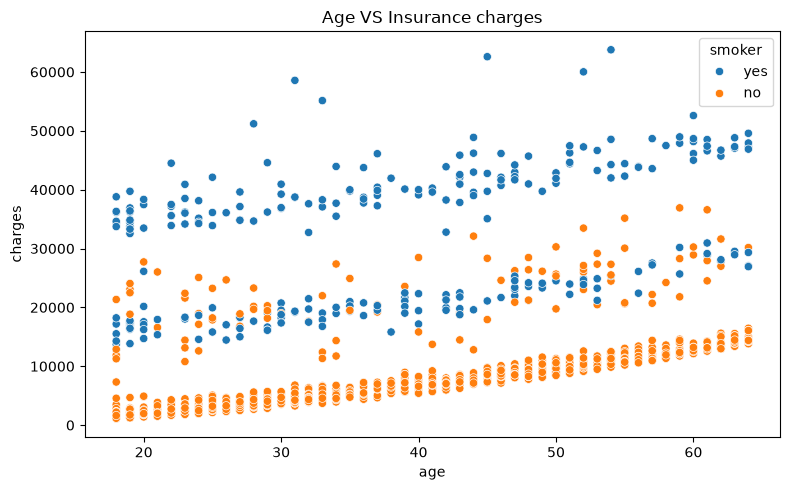

In [37]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data = df, x = "age", y = "charges", hue = "smoker")
plt.title("Age VS Insurance charges")
plt.tight_layout()
plt.show()

### BMI vs Insurance charge

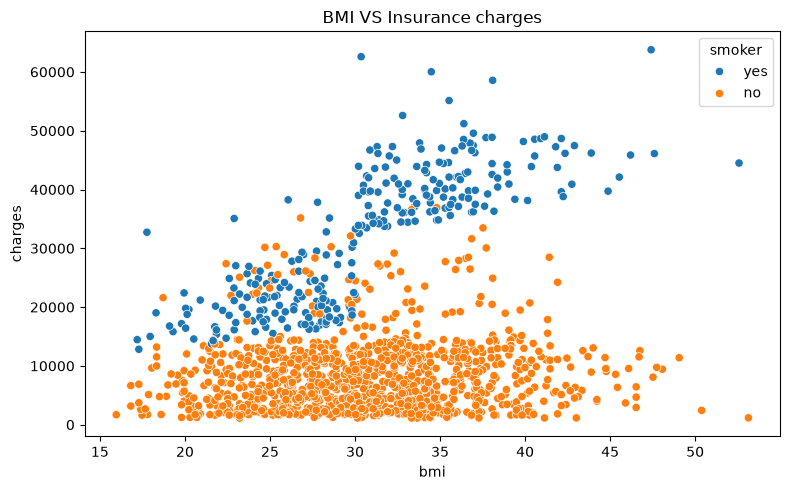

In [38]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data = df, x = "bmi", y = "charges", hue = "smoker")
plt.title("BMI VS Insurance charges")
plt.tight_layout()
plt.show()

### Smoker vs Insurance charges

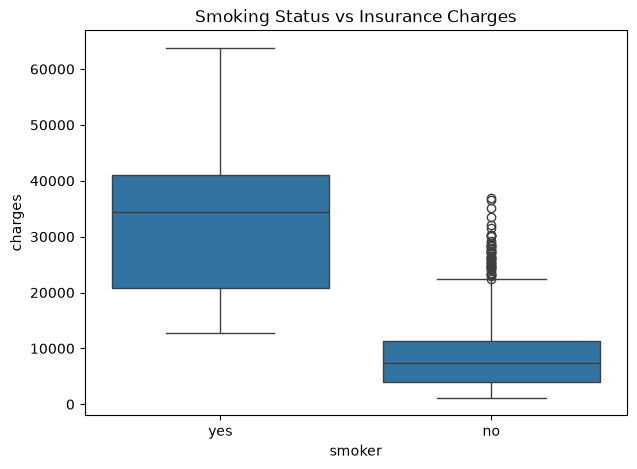

In [39]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='smoker',
    y='charges'
)

plt.title("Smoking Status vs Insurance Charges")

plt.show()

### Gender vs Insurance charges

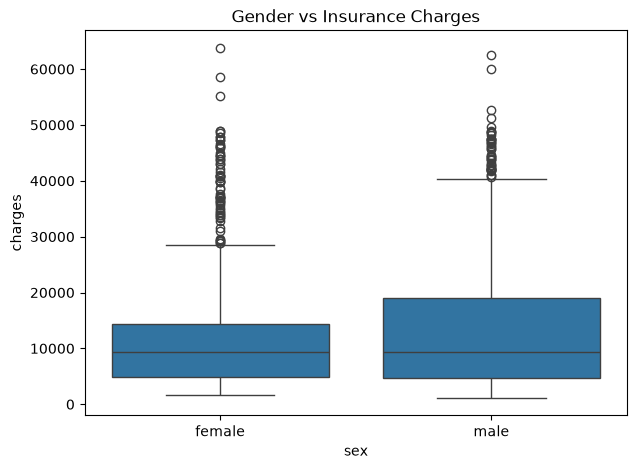

In [40]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='sex',
    y='charges'
)

plt.title("Gender vs Insurance Charges")

plt.show()

### Region vs Insurance Charges

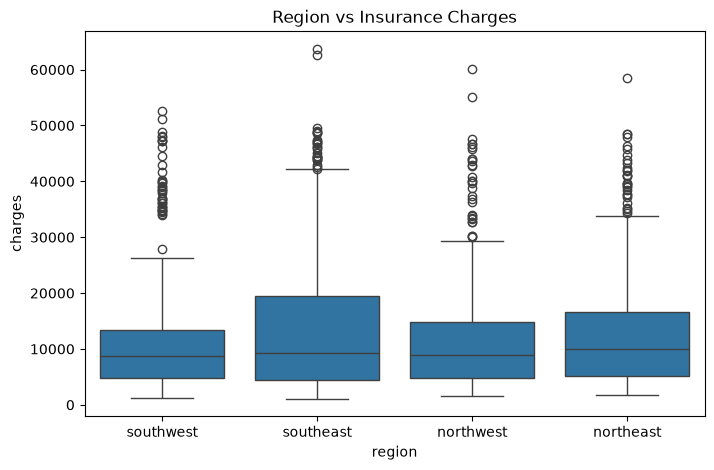

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='region',
    y='charges'
)

plt.title("Region vs Insurance Charges")

plt.show()

## Disclaimer 
* Insurance charges significantly increase for smoking person.
* Old aged or Young aged both somker person having high chance of having more insurance charges.
* Both high or low BMI person having high chance of having more insurance charges.
* smokers have significantly higher insurance expenses.
* Both gender(male, female) have similer type of insurance expences.
* No such role of regions for detecting insurance expences , northeast region having slightly high median insurance charge

### Feature Engineering

In [78]:
df["smoker_yes"] = df["smoker"].map({"yes" : 1, "no" : 0})

In [83]:
df["age_smoker"] = df["age"] * df["smoker_yes"]
df["bmi_smoker"] = df["bmi"] * df["smoker_yes"]

<Axes: >

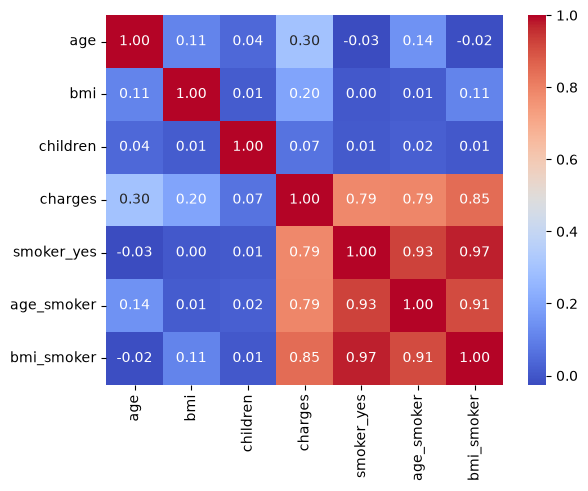

In [91]:
sns.heatmap(
    df.corr(numeric_only = True),
    cmap = "coolwarm",
    annot = True,
    fmt = ".2f"
)

In [92]:
df.dtypes

age             int64
sex            object
bmi           float64
children        int64
smoker         object
region         object
charges       float64
smoker_yes      int64
age_smoker      int64
bmi_smoker    float64
dtype: object

In [93]:
numerical_features = ["age", "bmi", "children", "age_smoker", "bmi_smoker"]
categorical_features = ["sex", "smoker", "region"]

In [94]:
X = df.drop(["charges", "smoker_yes"], axis = 1)
y = df["charges"]

In [95]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 42
)

In [96]:
numerical_preprocessor = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown = "ignore"))
])

In [97]:
preprocessor = ColumnTransformer([
    ("numerical", numerical_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

In [98]:
lr = LinearRegression()

lasso = Lasso(alpha = 0.1, max_iter = 1000)

ridge = Ridge(alpha = 1)

dt = DecisionTreeRegressor(
    random_state=42
)

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [99]:
models = {
    'Linear Regression': lr,

    'Ridge Regression': ridge,

    'Lasso Regression': lasso,

    'Decision Tree': dt,

    'Random Forest': rf
}

#### Create Complete ML Pipeline

In [100]:
model_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("Preprocessor", preprocessor),
        ("model", model)
    ])
    model_pipelines[name] = pipeline

#### Train the 5 Regressor model

In [101]:
for name, pipeline in model_pipelines.items():
    pipeline.fit(X_train, y_train)

    print(f"{name} fitted successfully")

Linear Regression fitted successfully
Ridge Regression fitted successfully
Lasso Regression fitted successfully
Decision Tree fitted successfully
Random Forest fitted successfully


In [102]:
from sklearn.model_selection import cross_validate, KFold

In [103]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'mae': 'neg_mean_absolute_error',

    'mse': 'neg_mean_squared_error',

    'r2': 'r2'
}

In [104]:
results = []

for name, pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    mae = -scores['test_mae'].mean()

    rmse = np.sqrt(-scores['test_mse'].mean())

    r2 = scores['test_r2'].mean()

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

    print(f"\n{name}")
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2:", r2)


Linear Regression
MAE: 2993.7208355188986
RMSE: 4952.728043256533
R2: 0.8182320700855058

Ridge Regression
MAE: 2996.1216737587793
RMSE: 4957.068490271556
R2: 0.8179805192391782

Lasso Regression
MAE: 2993.6871769757304
RMSE: 4952.701796289586
R2: 0.8182344647642529

Decision Tree
MAE: 3091.130046779738
RMSE: 6472.547096652047
R2: 0.6892230917284492

Random Forest
MAE: 2725.591570298094
RMSE: 4884.659510693501
R2: 0.8219245457975519


In [105]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
)

results_df

,Model,MAE,RMSE,R2 Score
4,Random Forest,2725.591570,4884.659511,0.821925
2,Lasso Regression,2993.687177,4952.701796,0.818234
0,Linear Regression,2993.720836,4952.728043,0.818232
1,Ridge Regression,2996.121674,4957.068490,0.817981
3,Decision Tree,3091.130047,6472.547097,0.689223


In [112]:
prediction_results = []
for name, pipeline in model_pipelines.items():
    y_pred = pipeline.predict(X_test)
    prediction_results.append({
        "Model" : name,
        "MAE" : mean_absolute_error(y_test, y_pred),
        "RMSE" : np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score" : r2_score(y_test, y_pred)
    })

In [114]:
prediction_results_df = pd.DataFrame(prediction_results)
prediction_results_df.sort_values("RMSE", ascending = True)

,Model,MAE,RMSE,R2 Score
1,Ridge Regression,2831.115233,4567.658559,0.886461
2,Lasso Regression,2831.613165,4577.660225,0.885963
0,Linear Regression,2831.646978,4577.779551,0.885957
4,Random Forest,2609.547383,4719.441466,0.878790
3,Decision Tree,2704.129325,6050.053649,0.800806


## Hyperparameter Tuning

### Ridge Regression

In [118]:
ridge_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', Ridge())
    ]
)

ridge_params = {
    'model__alpha': [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information

In [119]:
print("Best Parameters:", ridge_grid.best_params_)

print("Best RMSE:", -ridge_grid.best_score_)

Best Parameters: {'model__alpha': 0.1}
Best RMSE: 4924.794947334251


In [120]:
best_ridge = ridge_grid.best_estimator_

### Lasso Regression

In [121]:
lasso_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', Lasso(max_iter=20000))
    ]
)

lasso_params = {
    'model__alpha': [0.001, 0.01, 0.1, 1, 10]
}

lasso_grid = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=20000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information

In [122]:
print("Best Parameters:", lasso_grid.best_params_)

print("Best RMSE:", -lasso_grid.best_score_)

Best Parameters: {'model__alpha': 1}
Best RMSE: 4924.872403770778


In [123]:
best_lasso = lasso_grid.best_estimator_

### Decision Tree Regressor

In [124]:
dt_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(random_state=42))
    ]
)

dt_params = {
    'model__max_depth': [3, 5, 10, None],

    'model__min_samples_split': [2, 5, 10],

    'model__min_samples_leaf': [1, 2, 4]
}

dt_grid = GridSearchCV(
    dt_pipeline,
    dt_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added

In [125]:
print("Best Parameters:", dt_grid.best_params_)

print("Best RMSE:", -dt_grid.best_score_)

Best Parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2}
Best RMSE: 4820.4935496245


In [126]:
best_dt = dt_grid.best_estimator_

### Random Forest Regressor

In [130]:
rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(random_state=42))
    ]
)

rf_params = {
    'model__n_estimators': [100, 200],

    'model__max_depth': [5, 10, None],

    'model__min_samples_split': [2, 5],

    'model__min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 

In [131]:
print("Best Parameters:", rf_grid.best_params_)

print("Best RMSE:", -rf_grid.best_score_)

Best Parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best RMSE: 4604.380533478418


In [132]:
best_rf = rf_grid.best_estimator_

## Compare all tuned model

In [134]:
final_models = {

    'Linear Regression': model_pipelines["Linear Regression"],

    'Ridge Tuned': best_ridge,

    'Lasso Tuned': best_lasso,

    'Decision Tree Tuned': best_dt,

    'Random Forest Tuned': best_rf

}

In [135]:
final_results = []

for name, model in final_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    r2 = r2_score(y_test, y_pred)

    final_results.append({

        'Model': name,

        'MAE': mae,

        'RMSE': rmse,

        'R2 Score': r2

    })

In [136]:
final_results_df = pd.DataFrame(final_results)

final_results_df.sort_values(
    by='RMSE',
    ascending=True
)

,Model,MAE,RMSE,R2 Score
4,Random Forest Tuned,2422.166935,4262.798957,0.901111
3,Decision Tree Tuned,2681.721070,4416.820776,0.893836
1,Ridge Tuned,2831.466334,4576.139748,0.886039
2,Lasso Tuned,2831.308617,4576.630635,0.886014
0,Linear Regression,2831.646978,4577.779551,0.885957


In [137]:
best_model_name = final_results_df.sort_values(
    by='RMSE',
    ascending=True
).iloc[0]['Model']

final_model = final_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest Tuned


In [139]:
import os
import joblib
os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/final_insurance_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!
